# Bài 20 — Experiment 3: Attention head diversity

Notebook khảo sát các attention map của bốn head trong Transformer encoder đã huấn luyện. Mỗi head được vẽ trên cùng một câu IMDb; bảng cosine similarity và entropy chỉ hỗ trợ mô tả phân phối, không tự chứng minh ý nghĩa ngôn ngữ của head.

**Câu hỏi thực nghiệm:** Multi-head attention có tạo ra các attention patterns khác nhau trong mô hình và ví dụ được chọn không?

> Dùng cùng seed, IMDb split, vocabulary, `d_model`, batch size và cách cài Transformer như Bài 19. Notebook huấn luyện một mô hình với `n_heads = 4`.

## 1. Dự đoán trước khi chạy

- Dự đoán về độ giống nhau giữa bốn head:
- Lý do:
- Mức độ tin cậy (0–100%):

Không sửa dự đoán ban đầu sau khi xem kết quả. Sau khi chạy, ghi nhận xét ngắn dựa trên các biểu đồ và số đo.

In [ ]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import pad_sequences

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

D_MODEL = 128
N_HEADS = 4
D_FF = 256
MAX_WORDS = 20_000
MAX_LENGTH = 128
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 1e-3
DROPOUT = 0.1

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print(f"n_heads={N_HEADS}, d_model={D_MODEL}, d_k={D_MODEL // N_HEADS}")

TensorFlow: 2.21.0
GPUs: []
n_heads=4, d_model=128, d_k=32


## 2. Dữ liệu IMDb và split cố định

Dùng cùng seed, vocabulary giới hạn 20.000 từ, độ dài tối đa 128 và cách chia train/validation/test như Bài 19. Mô hình được huấn luyện trên train set; attention được quan sát trên một ví dụ thuộc test set.

In [ ]:
(x_trainval_raw, y_trainval), (x_test_raw, y_test) = imdb.load_data(
    num_words=MAX_WORDS, seed=SEED
)
y_trainval = np.asarray(y_trainval, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

train_idx, val_idx = train_test_split(
    np.arange(len(y_trainval)),
    test_size=0.1,
    random_state=SEED,
    stratify=y_trainval,
)

def pad_reviews(sequences):
    return np.asarray(
        pad_sequences(sequences, maxlen=MAX_LENGTH, padding="post", truncating="post"),
        dtype=np.int32,
    )

x_train = pad_reviews([x_trainval_raw[i] for i in train_idx])
y_train = y_trainval[train_idx]
x_val = pad_reviews([x_trainval_raw[i] for i in val_idx])
y_val = y_trainval[val_idx]
x_test = pad_reviews(x_test_raw)

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (22500, 128) (22500,)
Validation: (2500, 128) (2500,)
Test: (25000, 128) (25000,)


## 3. Positional encoding và Transformer block

Tự ghép multi-head self-attention, residual, LayerNorm và FFN từ các lớp cơ bản. Không dùng `TransformerEncoderLayer`. `return_attention=True` trả về weights có shape `[batch, heads, query, key]`. Padding bị mask ở chiều key.

In [ ]:
def positional_encoding(max_length, d_model):
    positions = np.arange(max_length, dtype=np.float32)[:, None]
    dimensions = np.arange(d_model, dtype=np.float32)[None, :]
    rates = np.power(10000.0, -(2.0 * np.floor(dimensions / 2.0)) / d_model)
    angles = positions * rates
    pe = np.empty_like(angles)
    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])
    return tf.constant(pe[None, :, :], dtype=tf.float32)

class MultiHeadSelfAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.q_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.k_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.v_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.out_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.attention_dropout = tf.keras.layers.Dropout(dropout)

    def _split_heads(self, x):
        batch_size = tf.shape(x)[0]
        seq_len = tf.shape(x)[1]
        x = tf.reshape(x, [batch_size, seq_len, self.n_heads, self.d_k])
        return tf.transpose(x, [0, 2, 1, 3])

    def call(self, x, key_mask=None, training=False, return_attention=False):
        q = self._split_heads(self.q_proj(x))
        k = self._split_heads(self.k_proj(x))
        v = self._split_heads(self.v_proj(x))
        scores = tf.matmul(q, k, transpose_b=True) / tf.math.sqrt(
            tf.cast(self.d_k, tf.float32)
        )
        if key_mask is not None:
            key_mask = tf.cast(key_mask[:, None, None, :], tf.bool)
            scores = tf.where(key_mask, scores, tf.cast(-1e9, scores.dtype))
        weights = tf.nn.softmax(scores, axis=-1)
        context = tf.matmul(self.attention_dropout(weights, training=training), v)
        context = tf.transpose(context, [0, 2, 1, 3])
        shape = tf.shape(context)
        context = tf.reshape(context, [shape[0], shape[1], self.d_model])
        output = self.out_proj(context)
        if return_attention:
            return output, weights
        return output

class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.attention_residual_dropout = tf.keras.layers.Dropout(dropout)
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.ffn1 = tf.keras.layers.Dense(d_ff, activation="gelu")
        self.ffn_dropout = tf.keras.layers.Dropout(dropout)
        self.ffn2 = tf.keras.layers.Dense(d_model)
        self.ffn_residual_dropout = tf.keras.layers.Dropout(dropout)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

    def call(self, x, key_mask=None, training=False, return_attention=False):
        if return_attention:
            attn_out, weights = self.attention(
                x, key_mask=key_mask, training=training, return_attention=True
            )
        else:
            attn_out = self.attention(x, key_mask=key_mask, training=training)
        x = self.norm1(x + self.attention_residual_dropout(attn_out, training=training))
        ff = self.ffn2(self.ffn_dropout(self.ffn1(x), training=training))
        output = self.norm2(x + self.ffn_residual_dropout(ff, training=training))
        if return_attention:
            return output, weights
        return output

## 4. Classifier bốn heads

In [ ]:
class TransformerClassifier(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.embedding = tf.keras.layers.Embedding(MAX_WORDS, D_MODEL, mask_zero=False)
        self.position = positional_encoding(MAX_LENGTH, D_MODEL)
        self.input_dropout = tf.keras.layers.Dropout(DROPOUT)
        self.block = TransformerBlock(D_MODEL, N_HEADS, D_FF, DROPOUT)
        self.classifier = tf.keras.layers.Dense(1, activation="sigmoid")

    def call(self, token_ids, training=False, return_attention=False):
        valid_mask = tf.not_equal(token_ids, 0)
        x = self.embedding(token_ids) * tf.math.sqrt(tf.cast(D_MODEL, tf.float32))
        x = x + self.position[:, :tf.shape(token_ids)[1], :]
        x = self.input_dropout(x, training=training)
        if return_attention:
            x, weights = self.block(
                x, key_mask=valid_mask, training=training, return_attention=True
            )
        else:
            x = self.block(x, key_mask=valid_mask, training=training)
        mask = tf.cast(valid_mask[:, :, None], x.dtype)
        pooled = tf.reduce_sum(x * mask, axis=1) / tf.maximum(
            tf.reduce_sum(mask, axis=1), 1.0
        )
        prediction = self.classifier(pooled)
        if return_attention:
            return prediction, weights
        return prediction

model = TransformerClassifier()
_ = model(tf.zeros([1, MAX_LENGTH], dtype=tf.int32))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
print("Parameters:", model.count_params())
print("Input shape:", (None, MAX_LENGTH))

Parameters: 2692097
Input shape: (None, 128)


## 5. Huấn luyện và kiểm tra shape

Huấn luyện cùng train/validation split. Sau đó kiểm tra attention weights có dạng `[B, 4, T, T]`. Chạy đủ dữ liệu trước khi dùng quan sát trong báo cáo.

Epoch 1/3
352/352 - 203s - 577ms/step - accuracy: 0.8043 - loss: 0.4160 - val_accuracy: 0.8524 - val_loss: 0.3488
Epoch 2/3
352/352 - 197s - 559ms/step - accuracy: 0.9151 - loss: 0.2147 - val_accuracy: 0.8480 - val_loss: 0.4565
Epoch 3/3
352/352 - 198s - 564ms/step - accuracy: 0.9567 - loss: 0.1155 - val_accuracy: 0.8380 - val_loss: 0.5088
Training time: 598.57 seconds
Attention weights: (2, 4, 128, 128)


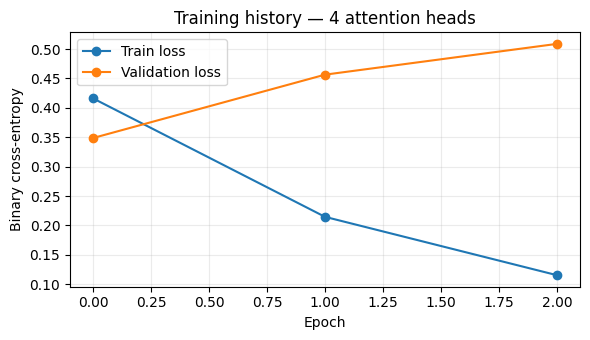

In [ ]:
started = time.perf_counter()
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=2,
)
training_seconds = time.perf_counter() - started
print(f"Training time: {training_seconds:.2f} seconds")

sample_batch = tf.convert_to_tensor(x_test[:2])
_, sample_weights = model(sample_batch, training=False, return_attention=True)
print("Attention weights:", tuple(sample_weights.shape))
assert tuple(sample_weights.shape) == (2, N_HEADS, MAX_LENGTH, MAX_LENGTH)

plt.figure(figsize=(6, 3.5))
plt.plot(history.history["loss"], marker="o", label="Train loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training history — 4 attention heads")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Chọn một review test và lấy attention weights

Chọn tự động một review có số token không padding trong khoảng 16–40 để nhãn trục đọc được. Nếu không có review phù hợp, chọn review gần 28 token. Hiển thị token, nhãn thật và dự đoán.

In [ ]:
valid_lengths = np.count_nonzero(x_test, axis=1)
candidates = np.flatnonzero((valid_lengths >= 16) & (valid_lengths <= 40))
if len(candidates):
    sample_index = int(candidates[0])
else:
    sample_index = int(np.argmin(np.abs(valid_lengths - 28)))

sample_ids = x_test[sample_index]
valid_length = int(valid_lengths[sample_index])
word_index = imdb.get_word_index()
index_word = {idx + 3: word for word, idx in word_index.items()}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"

tokens = [index_word.get(int(token_id), "<UNK>") for token_id in sample_ids[:valid_length]]
probability, attention = model(
    tf.convert_to_tensor(sample_ids[None, :]),
    training=False,
    return_attention=True,
)
predicted_label = int(float(probability[0, 0]) >= 0.5)
true_label = int(y_test[sample_index])
attention = attention.numpy()[0, :, :valid_length, :valid_length]

print("Test index:", sample_index)
print("Valid tokens:", valid_length)
print("True label:", "positive" if true_label else "negative")
print("Predicted label:", "positive" if predicted_label else "negative")
print(f"Predicted positive probability: {float(probability[0, 0]):.4f}")
print("Review tokens:", " ".join(tokens))
print("Attention per head:", attention.shape)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Test index: 98
Valid tokens: 33
True label: negative
Predicted label: negative
Predicted positive probability: 0.0001
Review tokens: <START> totally forgettable and almost unwatchable if you enjoy bad acting thin plots and predictably weak outcomes pull up a chair of passing interest to see bridget fonda look a like suzy <UNK>
Attention per head: (4, 33, 33)


## 7. Visualize từng attention head

Mỗi ô có query token trên trục dọc và key token trên trục ngang. Dùng cùng thang màu cho cả bốn heads để so sánh cường độ. Chỉ mô tả pattern nhìn thấy; không tự suy ra một head đại diện cho cú pháp, phủ định hoặc ý nghĩa.

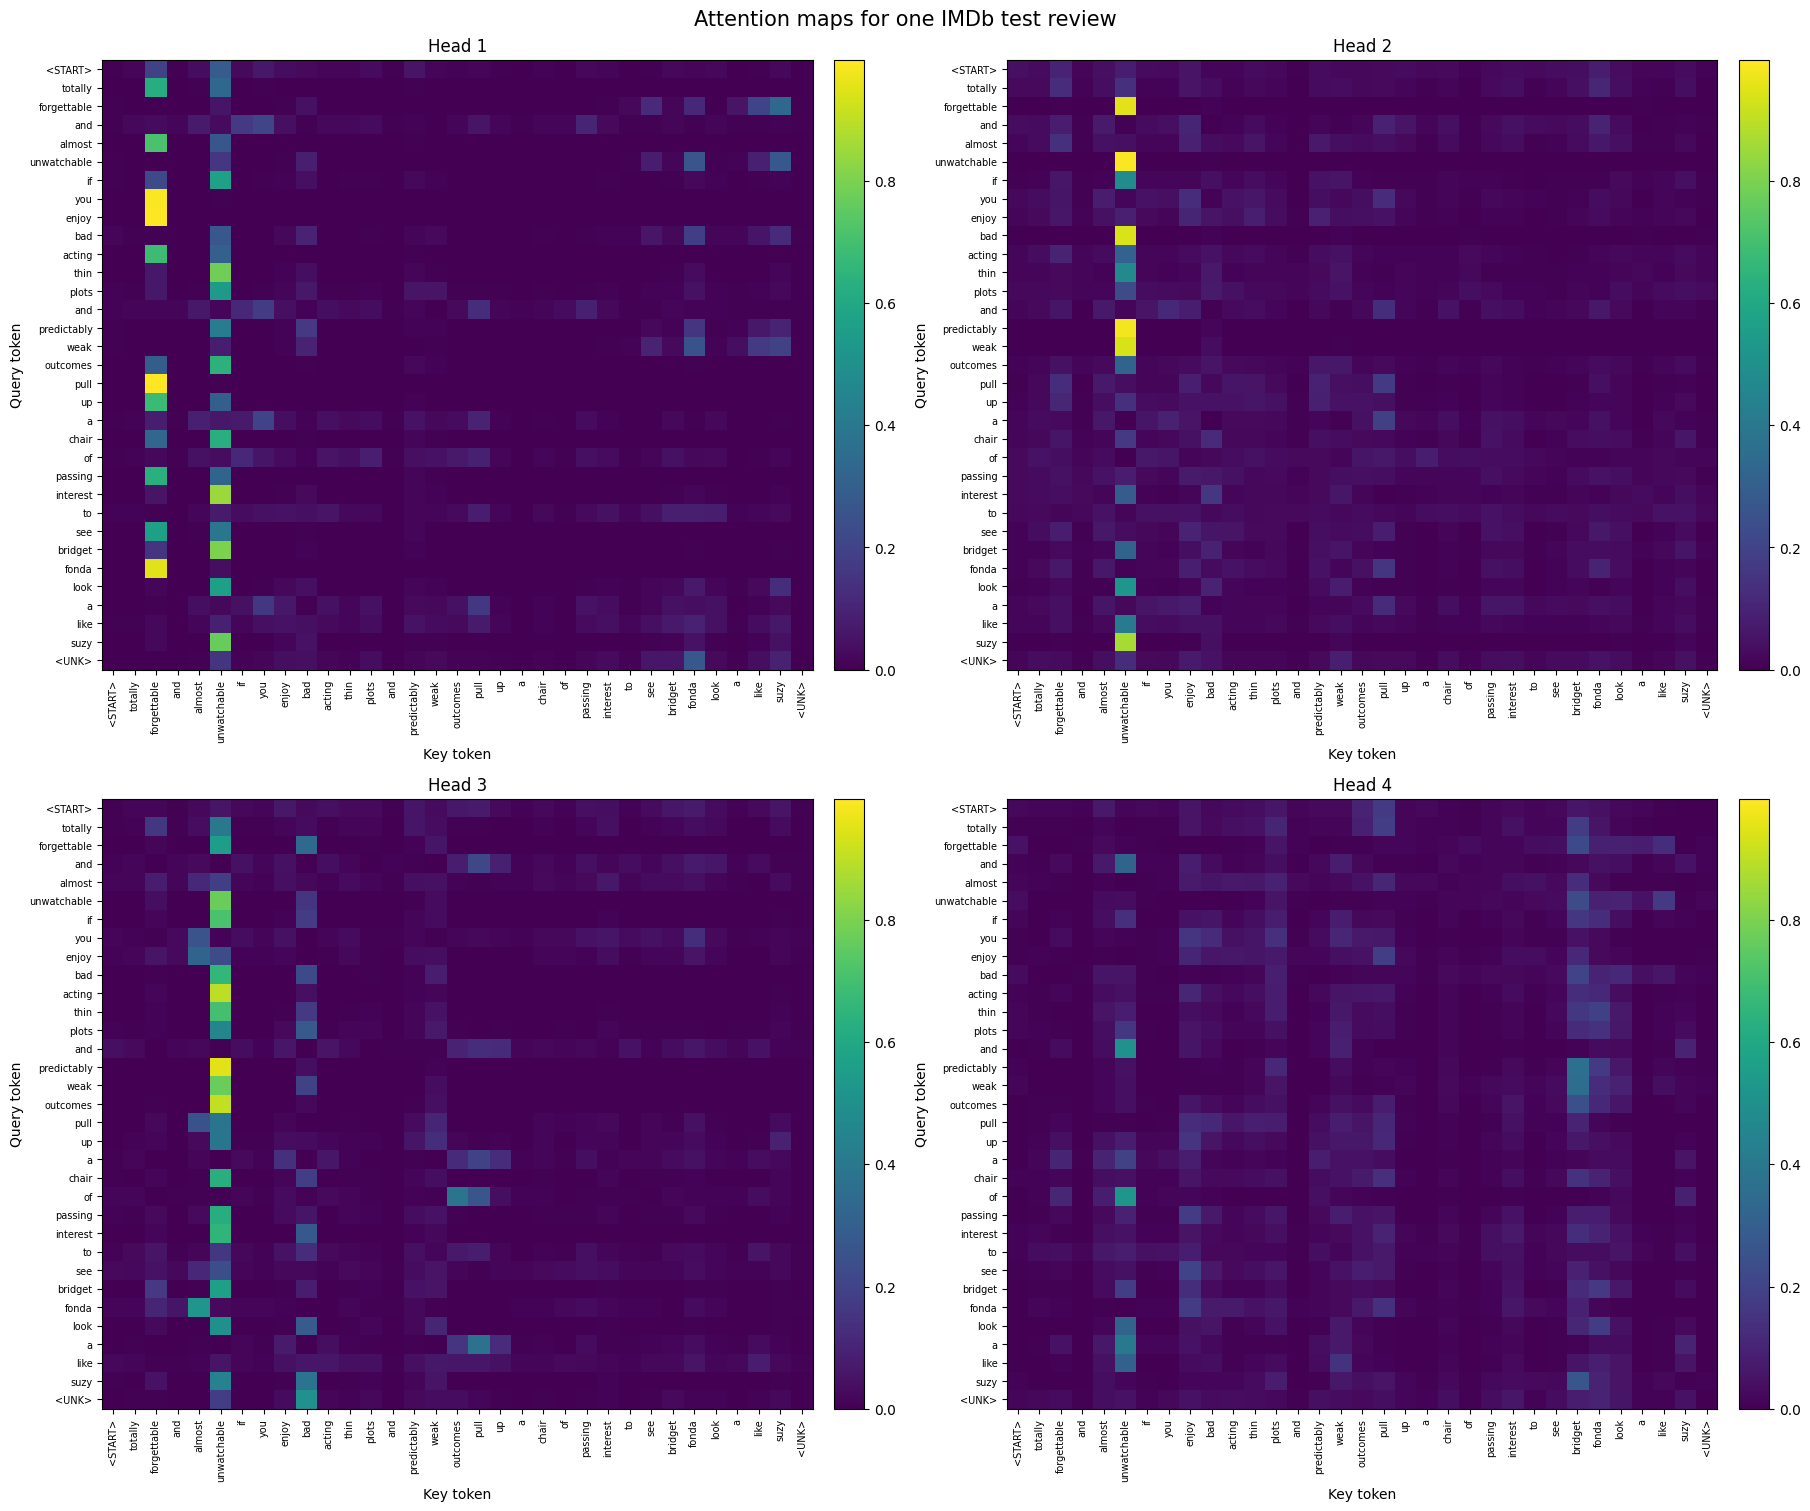

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(18, 15), constrained_layout=True)
vmax = float(attention.max())
for head, ax in enumerate(axes.flat):
    image = ax.imshow(
        attention[head], cmap="viridis", vmin=0.0, vmax=vmax,
        interpolation="nearest", aspect="auto"
    )
    ax.set_title(f"Head {head + 1}")
    ax.set_xticks(np.arange(valid_length))
    ax.set_yticks(np.arange(valid_length))
    ax.set_xticklabels(tokens, rotation=90, fontsize=7)
    ax.set_yticklabels(tokens, fontsize=7)
    ax.set_xlabel("Key token")
    ax.set_ylabel("Query token")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Attention maps for one IMDb test review", fontsize=15)
plt.show()

## 8. So sánh định lượng giữa các heads

Cosine similarity được tính trên các attention weights của cùng ví dụ, sau khi chỉ giữ query/key không padding. Entropy trung bình đo mức phân tán của weights trên các key. Đây là số đo mô tả phân phối, không phải kiểm định ý nghĩa hay bằng chứng rằng head có thể diễn giải theo một nhãn ngôn ngữ.

Pairwise cosine similarity:


,Head 1,Head 2,Head 3,Head 4
Head 1,1.000,0.485,0.540,0.228
Head 2,0.485,1.000,0.777,0.300
Head 3,0.540,0.777,1.000,0.231
Head 4,0.228,0.300,0.231,1.000


Mean entropy by head:


,Head,Mean attention entropy
0,1,1.598
1,2,2.495
2,3,1.891
3,4,2.737


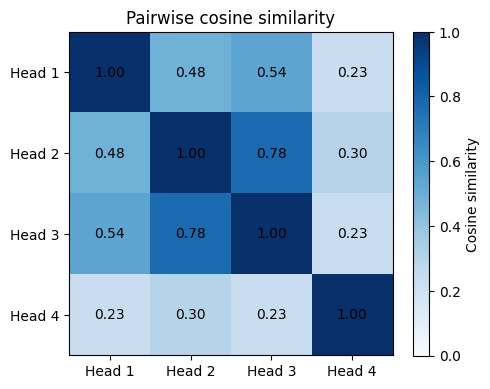

In [ ]:
flat_heads = attention.reshape(N_HEADS, -1)
norms = np.linalg.norm(flat_heads, axis=1, keepdims=True)
normalized = flat_heads / np.maximum(norms, 1e-12)
cosine_similarity = normalized @ normalized.T

safe_weights = np.clip(attention, 1e-12, 1.0)
head_entropy = -np.sum(safe_weights * np.log(safe_weights), axis=-1).mean(axis=1)
summary = pd.DataFrame({
    "Head": np.arange(1, N_HEADS + 1),
    "Mean attention entropy": head_entropy,
})
print("Pairwise cosine similarity:")
display(pd.DataFrame(
    cosine_similarity,
    index=[f"Head {i}" for i in range(1, N_HEADS + 1)],
    columns=[f"Head {i}" for i in range(1, N_HEADS + 1)],
).round(3))
print("Mean entropy by head:")
display(summary.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cosine_similarity, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_HEADS), [f"Head {i}" for i in range(1, N_HEADS + 1)])
ax.set_yticks(range(N_HEADS), [f"Head {i}" for i in range(1, N_HEADS + 1)])
ax.set_title("Pairwise cosine similarity")
for row in range(N_HEADS):
    for col in range(N_HEADS):
        ax.text(col, row, f"{cosine_similarity[row, col]:.2f}",
                ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="Cosine similarity")
plt.tight_layout()
plt.show()